In [1]:

import os

os.listdir('/content')


['.config', 'FPDSData.csv', 'mendeley dataset.zip', 'sample_data']

In [2]:

import os

files = os.listdir('/content')

for file in files:
    print(file)


.config
FPDSData.csv
mendeley dataset.zip
sample_data


In [3]:

import pandas as pd

# Load the DoD construction project dataset
df = pd.read_csv('/content/FPDSData.csv', low_memory=False)

# Display the first five rows
df.head()


,Contracting Agency ID,Contracting Agency Name,Contracting Office ID,Contracting Office Name,Country Where Award was Issued,Major Command Name,Modification Number,PIID,Referenced IDV PIID,Referenced IDV Mod Number,...,IDV Referenced IDV PIID,IDV Subcontract Plan,IDV Subcontract Plan Description,IDV Type Of IDC,IDV Type Of IDC Description,IDV Who Can Use,IDV Who Can Use Description,Base and Exercised Options Value,Action Obligation,Base and All Options Value (Total Contract Value)
0,1700,DEPT OF THE NAVY,M67001,COMMANDING GENERAL,USA,USMC,P00001,M6700107P0419,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-540.00,-540.00,-540.00
1,1700,DEPT OF THE NAVY,M67854,COMMANDER,USA,USMC,0,M6785411C8067,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3677241.05,3677241.05,3677241.05
2,1700,DEPT OF THE NAVY,M68909,SUPPLY OFFICER,USA,USMC,0,M6890911M1024,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3960.00,3960.00,3960.00
3,1700,DEPT OF THE NAVY,M68909,SUPPLY OFFICER,USA,USMC,0,M6890911M1026,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13312.00,13312.00,13312.00
4,1700,DEPT OF THE NAVY,N00189,NAVSUP FLT LOG CTR NORFOLK,USA,NAVSUP,P00008,N0018905P0992,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,-9994.00,0.00


In [4]:

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (360029, 61)

Column Names:
['Contracting Agency ID', 'Contracting Agency Name', 'Contracting Office ID', 'Contracting Office Name', 'Country Where Award was Issued', 'Major Command Name', 'Modification Number', 'PIID', 'Referenced  IDV PIID', 'Referenced IDV Mod Number', 'Transaction Number', 'Date Signed', 'Effective Date', 'Completion Date', 'Est. Ultimate Completion Date', 'Fiscal Year', 'Funding Agency ID', 'Funding Agency Name', 'Funding Department ID', 'Funding Department Name', 'Funding Office ID', 'Funding Office Name', '(Type of IDC)', 'Multiple or Single Award IDV', 'Multiyear Contract Code', 'Type of Contract', 'NAICS Code', 'NAICS Description', 'Principal Place of Performance State Code', 'Principal Place of Performance City Name', 'Principal Place of Performance Country Name', 'Place of Performance Zip Code', 'Product or Service Description', 'Product or Service Code', 'Description of Requirement', 'Award or IDV Type', 'Reason For Modification Description',

In [5]:

# Check for missing values in each column
missing_values = df.isnull().sum()

# Display the 20 columns with the most missing values
print("Missing Values:")
print(missing_values.sort_values(ascending=False).head(20))


Missing Values:
IDV Referenced IDV Agency Code              360029
IDV Referenced IDV PIID                     360029
IDV Major Program Code                      353279
(Type of IDC)                               346650
Multiple or Single Award IDV                345794
Treasury Account Symbol Sub Account Code    344549
IDV Type Of IDC                             145172
IDV Type Of IDC Description                 145172
IDV Who Can Use Description                 143293
IDV Who Can Use                             134867
IDV NAICS Description                       134583
IDV Subcontract Plan                        134276
IDV Subcontract Plan Description            134276
IDV NAICS Code                              133979
IDV Contracting Agency Name                 133958
IDV Department ID                           133958
IDV Department Name                         133958
IDV Type                                    133958
Referenced  IDV PIID                        133958
IDV Contracting

In [6]:

# Select financial columns
cost_columns = [
    'Base and Exercised Options Value',
    'Action Obligation',
    'Base and All Options Value (Total Contract Value)'
]

# Display summary statistics
df[cost_columns].describe()


,Base and Exercised Options Value,Action Obligation,Base and All Options Value (Total Contract Value)
count,3.457940e+05,3.600290e+05,3.600290e+05
mean,2.140429e+06,3.615032e+05,2.603101e+06
std,8.703254e+08,8.412701e+08,9.652591e+08
min,-3.447337e+11,-3.447337e+11,-3.447337e+11
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.382400e+04,1.122600e+04,1.165500e+04
75%,1.050285e+05,9.700000e+04,1.004579e+05
max,3.447339e+11,3.447339e+11,3.447339e+11


In [7]:

# Examine contract records
print("Total Rows:", len(df))
print("Unique Contract IDs:", df['PIID'].nunique())

# Examine modifications
print("\nModification Numbers:")
print(df['Modification Number'].value_counts().head(10))


Total Rows: 360029
Unique Contract IDs: 64123

Modification Numbers:
Modification Number
0         132662
1          39484
P00001     27506
2          19345
P00002     16176
3          10679
P00003     10308
P00004      6907
4           6390
P00005      4864
Name: count, dtype: int64


In [8]:

# Identify original awards and modifications
original = df[df['Modification Number'].astype(str) == '0']
modifications = df[df['Modification Number'].astype(str) != '0']

print("Original Award Records:", len(original))
print("Modification Records:", len(modifications))

print("\nOriginal Award Financial Statistics:")
print(original[
    ['Base and Exercised Options Value',
     'Action Obligation',
     'Base and All Options Value (Total Contract Value)']
].describe())


Original Award Records: 132662
Modification Records: 227367

Original Award Financial Statistics:
       Base and Exercised Options Value  Action Obligation  \
count                      1.297750e+05       1.326620e+05   
mean                       4.230361e+06       8.084607e+05   
std                        1.997569e+08       4.769739e+06   
min                        0.000000e+00       0.000000e+00   
25%                        2.326846e+04       2.028287e+04   
50%                        9.453499e+04       8.854076e+04   
75%                        3.668710e+05       3.480103e+05   
max                        3.145670e+10       6.460000e+08   

       Base and All Options Value (Total Contract Value)  
count                                       1.326620e+05  
mean                                        7.709531e+06  
std                                         4.129551e+08  
min                                         0.000000e+00  
25%                                         2.40

In [9]:

# Examine reasons for contract modifications
print("Top Modification Reasons:")

print(
    modifications['Reason For Modification Description']
    .value_counts()
    .head(15)
)


Top Modification Reasons:
Reason For Modification Description
SUPPLEMENTAL AGREEMENT FOR WORK WITHIN SCOPE               89547
OTHER ADMINISTRATIVE ACTION                                54508
CHANGE ORDER                                               51971
EXERCISE AN OPTION                                          9146
FUNDING ONLY ACTION                                         8797
CLOSE OUT                                                   5418
ADDITIONAL WORK (NEW AGREEMENT- JUSTIFICATION REQUIRED)     4550
DEFINITIZE CHANGE ORDER                                     1291
TERMINATE FOR CONVENIENCE (COMPLETE OR PARTIAL)             1186
VENDOR DUNS OR NAME CHANGE - NON-NOVATION                    369
TERMINATE FOR DEFAULT (COMPLETE OR PARTIAL)                  243
LEGAL CONTRACT CANCELLATION                                  129
VENDOR ADDRESS CHANGE                                         72
NOVATION AGREEMENT                                            56
TERMINATE FOR CAUSE         

In [10]:

# Check positive, negative, and zero financial values
cost = df['Base and All Options Value (Total Contract Value)']

print("Positive Values:", (cost > 0).sum())
print("Negative Values:", (cost < 0).sum())
print("Zero Values:", (cost == 0).sum())
print("Missing Values:", cost.isna().sum())


Positive Values: 229359
Negative Values: 30670
Zero Values: 100000
Missing Values: 0


In [11]:

# Check contract identifiers and dates
columns = [
    'Contracting Agency ID',
    'PIID',
    'Modification Number',
    'Date Signed',
    'Base and All Options Value (Total Contract Value)'
]

print(df[columns].head(15).to_string(index=False))

print("\nUnique agency and PIID combinations:")
print(
    df[['Contracting Agency ID', 'PIID']]
    .drop_duplicates()
    .shape[0]
)

print("\nMissing contract identifiers:")
print(
    df[['Contracting Agency ID', 'PIID']]
    .isna().sum()
)

print("\nRepeated original awards by agency and PIID:")
print(
    original.duplicated(
        subset=['Contracting Agency ID', 'PIID'],
        keep=False
    ).sum()
)


 Contracting Agency ID          PIID Modification Number Date Signed  Base and All Options Value (Total Contract Value)
                  1700 M6700107P0419              P00001  2011-07-05                                            -540.00
                  1700 M6785411C8067                   0  2011-09-29                                         3677241.05
                  1700 M6890911M1024                   0  2011-02-28                                            3960.00
                  1700 M6890911M1026                   0  2011-03-03                                           13312.00
                  1700 N0018905P0992              P00008  2011-05-31                                               0.00
                  1700          00A1                   0  2011-08-09                                           19055.40
                  1700          00A1                   1  2011-09-30                                            3252.75
                  1700             2    

In [12]:

# Check date formats and missing values
date_columns = [
    'Date Signed',
    'Effective Date',
    'Completion Date',
    'Est. Ultimate Completion Date'
]

print(df[date_columns].head(10).to_string(index=False))

print("\nMissing dates:")
print(df[date_columns].isna().sum())


Date Signed Effective Date Completion Date Est. Ultimate Completion Date
 2011-07-05     2008-11-21      2007-09-30                    2007-09-30
 2011-09-29     2011-09-28      2012-04-30                    2012-04-30
 2011-02-28     2011-02-28      2011-03-30                    2011-03-30
 2011-03-03     2011-03-04      2011-03-31                    2011-03-31
 2011-05-31     2011-05-18      2010-03-12                    2010-03-12
 2011-08-09     2011-08-09      2011-11-23                    2011-11-23
 2011-09-30     2011-09-30      2011-12-23                    2011-12-23
 2011-09-29     2011-09-29      2013-06-30                    2013-06-30
 2011-09-16     2011-09-16      2013-03-19                    2013-03-19
 2011-09-28     2011-09-28      2012-10-15                    2012-10-15

Missing dates:
Date Signed                          0
Effective Date                       0
Completion Date                  14235
Est. Ultimate Completion Date    14235
dtype: int64


In [13]:

# Examine contracts with repeated original award records
repeated = original[
    original.duplicated(
        subset=['Contracting Agency ID', 'PIID'],
        keep=False
    )
]

print("Repeated Original Award Records:", len(repeated))

print("\nExample Repeated Records:")
print(
    repeated[
        ['Contracting Agency ID',
         'PIID',
         'Transaction Number',
         'Date Signed',
         'Base and All Options Value (Total Contract Value)']
    ].head(20).to_string(index=False)
)


Repeated Original Award Records: 77646

Example Repeated Records:
 Contracting Agency ID PIID  Transaction Number Date Signed  Base and All Options Value (Total Contract Value)
                  1700    2                 0.0  2011-09-29                                         7174169.76
                  1700    3                 0.0  2011-09-16                                          741929.31
                  1700    3                 0.0  2011-09-28                                         2514208.00
                  1700   46                 0.0  2011-02-23                                           17339.57
                  1700   61                 0.0  2011-09-19                                           69439.47
                  1700   62                 0.0  2011-09-13                                          305547.55
                  1700   63                 0.0  2011-08-23                                           55776.00
                  1700   64                 0.

In [14]:

# Select an example contract with an original award
# and at least one modification

keys = ['Contracting Agency ID', 'PIID']

original_keys = original[keys].drop_duplicates()
modified_keys = modifications[keys].drop_duplicates()

common = original_keys.merge(modified_keys, on=keys)

print("Contracts with both award and modification records:",
      len(common))

if not common.empty:
    example = common.iloc[0]

    contract = df[
        (df['Contracting Agency ID'] == example['Contracting Agency ID']) &
        (df['PIID'] == example['PIID'])
    ].copy()

    contract['Date Signed'] = pd.to_datetime(
        contract['Date Signed'], errors='coerce'
    )

    contract = contract.sort_values('Date Signed')

    print("\nExample Contract History:")
    print(
        contract[
            ['PIID',
             'Modification Number',
             'Transaction Number',
             'Date Signed',
             'Base and All Options Value (Total Contract Value)',
             'Action Obligation']
        ].head(20).to_string(index=False)
    )


Contracts with both award and modification records: 32710

Example Contract History:
         PIID Modification Number  Transaction Number Date Signed  Base and All Options Value (Total Contract Value)  Action Obligation
M6785411C8067                   0                 0.0  2011-09-29                                         3677241.05         3677241.05
M6785411C8067              P00002                 0.0  2013-02-07                                           36380.41           36380.41
M6785411C8067              P00003                 0.0  2018-01-11                                               0.00               0.00


In [15]:

# Compare different contract identification methods

keys1 = ['Contracting Agency ID', 'PIID']

keys2 = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID'
]

print("Unique Agency + PIID:",
      df[keys1].drop_duplicates().shape[0])

print("Unique Agency + Office + PIID:",
      df[keys2].drop_duplicates().shape[0])

print("\nRepeated Original Awards with Office Included:")

print(
    original.duplicated(
        subset=keys2,
        keep=False
    ).sum()
)

print("\nMissing Office IDs:")
print(df['Contracting Office ID'].isna().sum())


Unique Agency + PIID: 66698
Unique Agency + Office + PIID: 88201

Repeated Original Awards with Office Included:
65686

Missing Office IDs:
0


In [16]:

# Examine five contracts with original awards and modifications

keys = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID'
]

award_keys = original[keys].drop_duplicates()
mod_keys = modifications[keys].drop_duplicates()

common_contracts = award_keys.merge(mod_keys, on=keys)

print("Contracts with Awards and Modifications:",
      len(common_contracts))

for _, item in common_contracts.head(5).iterrows():

    mask = (
        (df['Contracting Agency ID'] == item['Contracting Agency ID']) &
        (df['Contracting Office ID'] == item['Contracting Office ID']) &
        (df['PIID'] == item['PIID'])
    )

    contract = df.loc[mask].sort_values('Date Signed')

    print("\nContract:", item['PIID'])

    print(
        contract[
            ['Modification Number',
             'Date Signed',
             'Base and All Options Value (Total Contract Value)']
        ].head(10).to_string(index=False)
    )


Contracts with Awards and Modifications: 44278

Contract: M6785411C8067
Modification Number Date Signed  Base and All Options Value (Total Contract Value)
                  0  2011-09-29                                         3677241.05
             P00002  2013-02-07                                           36380.41
             P00003  2018-01-11                                               0.00

Contract: 00A1
Modification Number Date Signed  Base and All Options Value (Total Contract Value)
                  0  2011-08-09                                           19055.40
                  1  2011-09-30                                            3252.75

Contract: 2
Modification Number Date Signed  Base and All Options Value (Total Contract Value)
                  0  2010-09-16                                          318960.84
                  0  2010-09-30                                          316453.41
                 10  2011-03-23                                      

In [17]:

# Step 18: Identify contracts with one original award

keys = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID'
]

# Count original award records for each identifier
award_counts = (
    original.groupby(keys)
    .size()
    .reset_index(name='Original Award Count')
)

# Keep identifiers with exactly one original award
single_awards = award_counts[
    award_counts['Original Award Count'] == 1
]

print("Groups with exactly one original award:",
      len(single_awards))

# Find original awards for these groups
clean_original = original.merge(
    single_awards[keys],
    on=keys,
    how='inner'
)

print("Original award records retained:",
      len(clean_original))

print("\nOriginal award value statistics:")
print(
    clean_original[
        'Base and All Options Value (Total Contract Value)'
    ].describe()
)


Groups with exactly one original award: 66976
Original award records retained: 66976

Original award value statistics:
count    6.697600e+04
mean     1.217985e+07
std      5.766173e+08
min      0.000000e+00
25%      2.380869e+04
50%      1.083792e+05
75%      5.005418e+05
max      6.000000e+10
Name: Base and All Options Value (Total Contract Value), dtype: float64


In [18]:

# Step 19: Find contracts with one original award
# and at least one modification

clean_keys = clean_original[keys].drop_duplicates()
mod_keys = modifications[keys].drop_duplicates()

eligible = clean_keys.merge(
    mod_keys,
    on=keys,
    how='inner'
)

print("Single-award groups with modifications:",
      len(eligible))

# Display a few examples
print("\nExample contract identifiers:")
print(eligible.head(10).to_string(index=False))


Single-award groups with modifications: 35408

Example contract identifiers:
 Contracting Agency ID Contracting Office ID          PIID
                  1700                M67854 M6785411C8067
                  1700                N00604          00A1
                  1700                N33191 N3319111C1723
                  1700                N33191 N3319111P1720
                  1700                N33191 N3319111P1722
                  1700                N33191 N3319111P1742
                  1700                N40080           495
                  1700                N40080           540
                  1700                N40080           578
                  1700                N40080           704


In [19]:

# Step 20: Examine modification financial values

cost_col = 'Base and All Options Value (Total Contract Value)'

# Keep modifications associated with single-award groups
clean_modifications = modifications.merge(
    clean_keys,
    on=keys,
    how='inner'
)

print("Modification records retained:",
      len(clean_modifications))

print("\nModification Financial Summary:")
print(clean_modifications[cost_col].describe())

print("\nPositive modifications:",
      (clean_modifications[cost_col] > 0).sum())

print("Negative modifications:",
      (clean_modifications[cost_col] < 0).sum())

print("Zero modifications:",
      (clean_modifications[cost_col] == 0).sum())

print("Missing values:",
      clean_modifications[cost_col].isna().sum())


Modification records retained: 107080

Modification Financial Summary:
count    1.070800e+05
mean     1.704258e+05
std      4.030687e+08
min     -9.249016e+10
25%      0.000000e+00
50%      0.000000e+00
75%      1.942525e+04
max      9.249072e+10
Name: Base and All Options Value (Total Contract Value), dtype: float64

Positive modifications: 44441
Negative modifications: 12726
Zero modifications: 49913
Missing values: 0


In [20]:

# Step 21: Calculate preliminary contract value growth

# Sum modification values for each contract group
mod_totals = (
    clean_modifications.groupby(keys)[cost_col]
    .sum()
    .reset_index(name='Modification Total')
)

# Combine with original award values
project_data = clean_original.merge(
    mod_totals,
    on=keys,
    how='left'
)

# Contracts without modifications receive zero
project_data['Modification Total'] = (
    project_data['Modification Total'].fillna(0)
)

# Keep contracts with positive original award values
project_data = project_data[
    project_data[cost_col] > 0
].copy()

# Calculate preliminary growth percentage
project_data['Cost Growth Percent'] = (
    project_data['Modification Total'] /
    project_data[cost_col]
) * 100

print("Projects retained:", len(project_data))

print("\nPreliminary Cost Growth Statistics:")
print(project_data['Cost Growth Percent'].describe())

print("\nProjects with Positive Cost Growth:",
      (project_data['Cost Growth Percent'] > 0).sum())

print("Projects with No Positive Cost Growth:",
      (project_data['Cost Growth Percent'] <= 0).sum())


Projects retained: 66810

Preliminary Cost Growth Statistics:
count    6.681000e+04
mean     1.995894e+05
std      5.126199e+07
min     -2.884508e+04
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.325000e+10
Name: Cost Growth Percent, dtype: float64

Projects with Positive Cost Growth: 15028
Projects with No Positive Cost Growth: 51782


In [21]:

# Step 22: Investigate extreme cost growth values

print("Top 10 Highest Cost Growth Percentages:")

print(
    project_data[
        ['PIID',
         'Base and All Options Value (Total Contract Value)',
         'Modification Total',
         'Cost Growth Percent']
    ]
    .sort_values('Cost Growth Percent', ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nProjects with growth greater than 100%:",
      (project_data['Cost Growth Percent'] > 100).sum())

print("Projects with growth below -100%:",
      (project_data['Cost Growth Percent'] < -100).sum())


Top 10 Highest Cost Growth Percentages:
         PIID  Base and All Options Value (Total Contract Value)  Modification Total  Cost Growth Percent
FA442713D0102                                               0.01          1325000.00         1.325000e+10
FA303012D0002                                              42.44          3999957.56         9.424971e+06
FA483018F9129                                              10.00           863251.83         8.632518e+06
          111                                             149.83         11945444.00         7.972665e+06
FA483018F9124                                              10.00           442905.79         4.429058e+06
FA483018F9121                                              10.00           356276.26         3.562763e+06
FA483018F9166                                              10.00           295899.49         2.958995e+06
FA483018F9137                                              10.00           258172.76         2.581728e+06
FA4830

In [22]:

# Step 23: Examine original award values

original_cost = project_data[
    'Base and All Options Value (Total Contract Value)'
]

print("Original Awards Below $1,000:",
      (original_cost < 1000).sum())

print("Original Awards Between $1,000 and $10,000:",
      ((original_cost >= 1000) &
       (original_cost < 10000)).sum())

print("Original Awards $10,000 or More:",
      (original_cost >= 10000).sum())

print("\nOriginal Award Percentiles:")
print(
    original_cost.quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)


Original Awards Below $1,000: 821
Original Awards Between $1,000 and $10,000: 8609
Original Awards $10,000 or More: 57380

Original Award Percentiles:
0.01    7.027412e+02
0.05    4.001570e+03
0.25    2.403482e+04
0.50    1.090000e+05
0.75    5.033200e+05
0.95    7.741057e+06
0.99    6.400000e+07
Name: Base and All Options Value (Total Contract Value), dtype: float64


In [23]:

# Step 24: Inspect transaction values for one contract

example = df[
    df['PIID'].astype(str) == 'M6785411C8067'
].copy()

example['Date Signed'] = pd.to_datetime(
    example['Date Signed'], errors='coerce'
)

example = example.sort_values('Date Signed')

columns = [
    'PIID',
    'Modification Number',
    'Date Signed',
    'Base and Exercised Options Value',
    'Base and All Options Value (Total Contract Value)',
    'Action Obligation'
]

print(example[columns].to_string(index=False))


         PIID Modification Number Date Signed  Base and Exercised Options Value  Base and All Options Value (Total Contract Value)  Action Obligation
M6785411C8067                   0  2011-09-29                        3677241.05                                         3677241.05         3677241.05
M6785411C8067              P00002  2013-02-07                          36380.41                                           36380.41           36380.41
M6785411C8067              P00003  2018-01-11                              0.00                                               0.00               0.00


In [24]:

# Step 25: Find additional contract identification fields

print("Possible contract identification columns:")

for col in df.columns:
    if any(word in col.lower() for word in [
        'agency', 'office', 'piid',
        'contract', 'award', 'transaction', 'idv'
    ]):
        print(col)


Possible contract identification columns:
Contracting Agency ID
Contracting Agency Name
Contracting Office ID
Contracting Office Name
Country Where Award was Issued
PIID
Referenced  IDV PIID
Referenced IDV Mod Number
Transaction Number
Funding Agency ID
Funding Agency Name
Funding Office ID
Funding Office Name
Multiple or Single Award IDV
Multiyear Contract Code
Type of Contract
Award or IDV Type
IDV Type
Treasury Account Symbol Agency Identifier
IDV NAICS Code
IDV NAICS Description
IDV Contracting Agency ID
IDV Contracting Agency Name
IDV Department ID
IDV Department Name
IDV Major Program Code
IDV Referenced IDV Agency Code
IDV Referenced IDV PIID
IDV Subcontract Plan
IDV Subcontract Plan Description
IDV Type Of IDC
IDV Type Of IDC Description
IDV Who Can Use
IDV Who Can Use Description
Base and All Options Value (Total Contract Value)


In [25]:

# Step 26: Check duplicate contract transactions

transaction_keys = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID',
    'Modification Number',
    'Transaction Number'
]

print("Total Records:", len(df))

print("Duplicate Transaction Keys:",
      df.duplicated(subset=transaction_keys).sum())

print("\nExample Duplicate Transactions:")

duplicates = df[
    df.duplicated(subset=transaction_keys, keep=False)
]

print(
    duplicates[
        transaction_keys +
        ['Date Signed',
         'Base and All Options Value (Total Contract Value)']
    ].head(15).to_string(index=False)
)


Total Records: 360029
Duplicate Transaction Keys: 108771

Example Duplicate Transactions:
 Contracting Agency ID Contracting Office ID PIID Modification Number  Transaction Number Date Signed  Base and All Options Value (Total Contract Value)
                  1700                N33191    2                   0                 0.0  2011-09-29                                         7174169.76
                  1700                N33191    3                   0                 0.0  2011-09-16                                          741929.31
                  1700                N33191    3                   0                 0.0  2011-09-28                                         2514208.00
                  1700                N33191   46                   0                 0.0  2011-02-23                                           17339.57
                  1700                N33191   61                   0                 0.0  2011-09-19                                           6

In [26]:

# Step 27: Examine contract types

print("Award or IDV Types:")

print(
    df['Award or IDV Type']
    .value_counts(dropna=False)
    .head(15)
)

print("\nContract Types:")

print(
    df['Type of Contract']
    .value_counts(dropna=False)
    .head(15)
)


Award or IDV Types:
Award or IDV Type
DELIVERY ORDER         222119
DEFINITIVE CONTRACT    101429
PURCHASE ORDER          18294
IDC                     13560
BPA CALL                 3952
BPA                       482
BOA                       193
Name: count, dtype: int64

Contract Types:
Type of Contract
FIRM FIXED PRICE                                                                               351366
ORDER DEPENDENT (IDV ALLOWS PRICING ARRANGEMENT TO BE DETERMINED SEPARATELY FOR EACH ORDER)      2034
COST PLUS FIXED FEE                                                                              1400
COST PLUS AWARD FEE                                                                              1387
FIXED PRICE WITH ECONOMIC PRICE ADJUSTMENT                                                       1285
FIXED PRICE                                                                                       976
TIME AND MATERIALS                                                              

In [27]:

# Step 28: Focus on definitive contracts

definitive = df[
    df['Award or IDV Type'] == 'DEFINITIVE CONTRACT'
].copy()

print("Definitive Contract Records:", len(definitive))

print("\nUnique Agency + Office + PIID:")
print(
    definitive[
        ['Contracting Agency ID',
         'Contracting Office ID',
         'PIID']
    ].drop_duplicates().shape[0]
)

print("\nOriginal Award Records:")
print(
    (definitive['Modification Number'].astype(str) == '0').sum()
)

print("\nModification Records:")
print(
    (definitive['Modification Number'].astype(str) != '0').sum()
)


Definitive Contract Records: 101429

Unique Agency + Office + PIID:
23390

Original Award Records:
18067

Modification Records:
83362


In [28]:

# Step 29: Check duplicates within definitive contracts

transaction_keys = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID',
    'Modification Number',
    'Transaction Number'
]

print("Duplicate Transaction Keys:")
print(
    definitive.duplicated(
        subset=transaction_keys
    ).sum()
)

print("\nExamples of Repeated Transactions:")

repeated = definitive[
    definitive.duplicated(
        subset=transaction_keys,
        keep=False
    )
]

print(
    repeated[
        transaction_keys +
        ['Date Signed',
         'Base and All Options Value (Total Contract Value)']
    ].head(15).to_string(index=False)
)


Duplicate Transaction Keys:
0

Examples of Repeated Transactions:
Empty DataFrame
Columns: [Contracting Agency ID, Contracting Office ID, PIID, Modification Number, Transaction Number, Date Signed, Base and All Options Value (Total Contract Value)]
Index: []


In [29]:

# Step 30: Identify definitive contracts with one original award

keys = [
    'Contracting Agency ID',
    'Contracting Office ID',
    'PIID'
]

original_def = definitive[
    definitive['Modification Number'].astype(str) == '0'
].copy()

mod_def = definitive[
    definitive['Modification Number'].astype(str) != '0'
].copy()

award_counts = original_def.groupby(keys).size()

print("Groups with exactly one original award:",
      (award_counts == 1).sum())

print("Groups with multiple original awards:",
      (award_counts > 1).sum())

print("Groups with no original award:",
      len(
          definitive[keys].drop_duplicates()
      ) - len(award_counts))


Groups with exactly one original award: 18045
Groups with multiple original awards: 11
Groups with no original award: 5334


In [30]:

# Step 31: Identify contracts suitable for initial analysis

single_keys = award_counts[
    award_counts == 1
].reset_index()[keys]

eligible_original = original_def.merge(
    single_keys,
    on=keys,
    how='inner'
)

eligible_mod = mod_def.merge(
    single_keys,
    on=keys,
    how='inner'
)

print("Eligible Original Awards:", len(eligible_original))

print("Associated Modification Records:", len(eligible_mod))

print("Eligible Contracts with Modifications:",
      eligible_mod[keys].drop_duplicates().shape[0])

print("Eligible Contracts without Modifications:",
      len(eligible_original) -
      eligible_mod[keys].drop_duplicates().shape[0])


Eligible Original Awards: 18045
Associated Modification Records: 62802
Eligible Contracts with Modifications: 13648
Eligible Contracts without Modifications: 4397


In [31]:

# Step 32: Create preliminary contract growth labels

import pandas as pd

cost_col = 'Base and All Options Value (Total Contract Value)'

# Convert financial values to numeric
eligible_original = eligible_original.copy()
eligible_mod = eligible_mod.copy()

eligible_original[cost_col] = pd.to_numeric(
    eligible_original[cost_col], errors='coerce'
)

eligible_mod[cost_col] = pd.to_numeric(
    eligible_mod[cost_col], errors='coerce'
)

# Sum modification values for each contract group
mod_totals = (
    eligible_mod.groupby(keys)[cost_col]
    .sum(min_count=1)
    .reset_index(name='Modification Total')
)

# Combine original awards with modifications
project_data = eligible_original.merge(
    mod_totals, on=keys, how='left'
)

project_data['Modification Total'] = (
    project_data['Modification Total'].fillna(0)
)

# Keep positive original awards of at least $10,000
project_data = project_data[
    project_data[cost_col] >= 10000
].copy()

# Calculate preliminary percentage growth
project_data['Cost Growth Percent'] = (
    project_data['Modification Total'] /
    project_data[cost_col]
) * 100

# Binary classification target
project_data['Cost Growth Label'] = (
    project_data['Cost Growth Percent'] > 0
).astype(int)

print("Contracts Retained:", len(project_data))

print("\nClassification Counts:")
print(project_data['Cost Growth Label'].value_counts())

print("\nGrowth Statistics:")
print(project_data['Cost Growth Percent'].describe())


Contracts Retained: 17647

Classification Counts:
Cost Growth Label
0    10390
1     7257
Name: count, dtype: int64

Growth Statistics:
count     17647.000000
mean         29.538156
std         930.616351
min        -111.710198
25%           0.000000
50%           0.000000
75%           5.101864
max      103246.979240
Name: Cost Growth Percent, dtype: float64


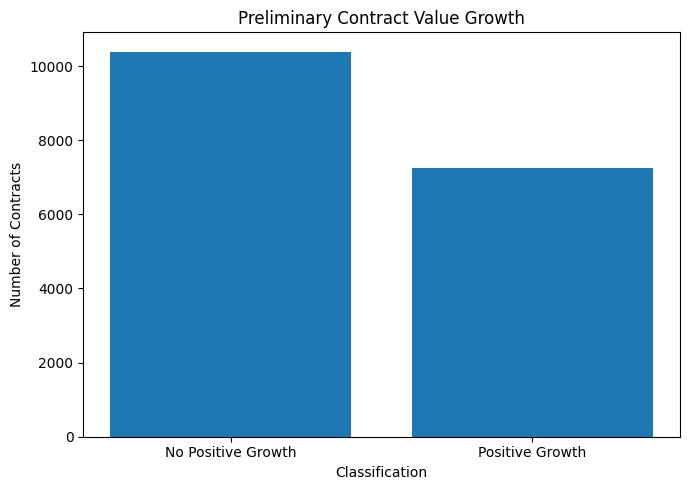

In [32]:

# Step 33: Visualize preliminary classification labels

import matplotlib.pyplot as plt

counts = (
    project_data['Cost Growth Label']
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(7, 5))

plt.bar(
    ['No Positive Growth', 'Positive Growth'],
    counts.values
)

plt.title('Preliminary Contract Value Growth')
plt.xlabel('Classification')
plt.ylabel('Number of Contracts')

plt.tight_layout()
plt.show()


In [33]:

# Step 34: Examine potential prediction features

features = [
    'Base and All Options Value (Total Contract Value)',
    'Type of Contract',
    'Contracting Agency ID',
    'Contracting Office ID',
    'Date Signed'
]

print("Available Prediction Features:\n")

for col in features:
    if col in project_data.columns:
        print(col, "- Available")
        print("Missing Values:", project_data[col].isna().sum())
        print()
    else:
        print(col, "- NOT FOUND")


Available Prediction Features:

Base and All Options Value (Total Contract Value) - Available
Missing Values: 0

Type of Contract - Available
Missing Values: 0

Contracting Agency ID - Available
Missing Values: 0

Contracting Office ID - Available
Missing Values: 0

Date Signed - Available
Missing Values: 0



In [34]:

# Step 35: Compare original award values by class

cost_col = 'Base and All Options Value (Total Contract Value)'

print("Original Award Values by Growth Classification:\n")

print(
    project_data.groupby('Cost Growth Label')[cost_col]
    .describe()
)


Original Award Values by Growth Classification:

                     count          mean           std       min          25%  \
Cost Growth Label                                                               
0                  10390.0  2.584141e+06  6.172834e+07  10000.00  110231.2675   
1                   7257.0  4.219121e+07  8.113180e+08  10078.17  347850.0000   

                          50%           75%           max  
Cost Growth Label                                          
0                   335704.50  9.979872e+05  6.198679e+09  
1                  1125890.34  3.850132e+06  3.145670e+10  


In [35]:

# Step 36: Train the first Logistic Regression model

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Create award-time prediction features
model_data = project_data.copy()

model_data['Log Original Value'] = np.log1p(
    model_data[cost_col]
)

model_data['Award Year'] = pd.to_datetime(
    model_data['Date Signed'], errors='coerce'
).dt.year

# Select inputs and target
feature_cols = [
    'Log Original Value',
    'Award Year',
    'Type of Contract'
]

model_data = model_data.dropna(
    subset=feature_cols + ['Cost Growth Label']
)

X = model_data[feature_cols]
y = model_data['Cost Growth Label']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Prepare numeric and categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(),
         ['Log Original Value', 'Award Year']),
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         ['Type of Contract'])
    ]
)

# Create model pipeline
logistic_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
logistic_model.fit(X_train, y_train)

# Predict test data
y_pred = logistic_model.predict(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nLogistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred,
                                        zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred,
                                     zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred,
                                   zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Training Samples: 14117
Testing Samples: 3530

Logistic Regression Results
Accuracy: 0.6521
Precision: 0.6102
Recall: 0.427
F1 Score: 0.5024

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.81      0.73      2078
           1       0.61      0.43      0.50      1452

    accuracy                           0.65      3530
   macro avg       0.64      0.62      0.62      3530
weighted avg       0.64      0.65      0.64      3530



Majority Class Baseline Accuracy: 0.5887
Logistic Regression Accuracy: 0.6521


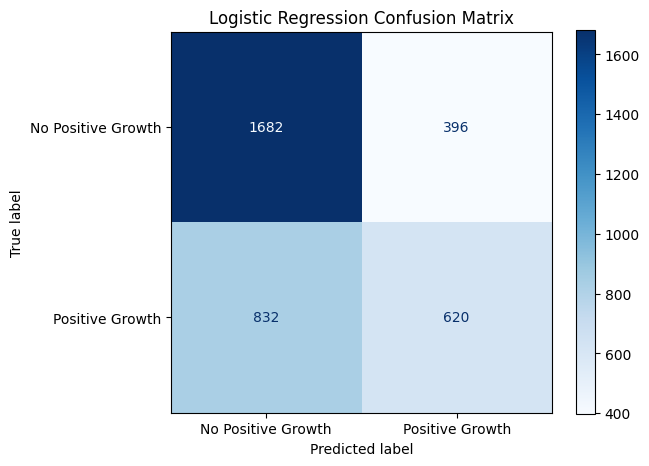

In [36]:

# Step 37: Evaluate the model against a simple baseline

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Baseline: predict the most common training class
majority_class = y_train.mode()[0]
baseline_predictions = np.full(len(y_test), majority_class)

print("Majority Class Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No Positive Growth', 'Positive Growth'],
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()


In [37]:

# Step 38: Train a Gaussian Naive Bayes model

from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

# Use the same training and testing data as Logistic Regression
nb_preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(),
         ['Log Original Value', 'Award Year']),
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         ['Type of Contract'])
    ],
    sparse_threshold=0
)

naive_bayes_model = Pipeline([
    ('preprocessing', nb_preprocessor),
    ('classifier', GaussianNB())
])

# Train the model
naive_bayes_model.fit(X_train, y_train)

# Predict the test set
nb_pred = naive_bayes_model.predict(X_test)

print("Gaussian Naive Bayes Results")
print("Accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred,
                                         zero_division=0), 4))
print("Recall:", round(recall_score(y_test, nb_pred,
                                      zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, nb_pred,
                                    zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, nb_pred, zero_division=0))


Gaussian Naive Bayes Results
Accuracy: 0.5881
Precision: 0.25
Recall: 0.0007
F1 Score: 0.0014

Classification Report:
              precision    recall  f1-score   support

           0       0.59      1.00      0.74      2078
           1       0.25      0.00      0.00      1452

    accuracy                           0.59      3530
   macro avg       0.42      0.50      0.37      3530
weighted avg       0.45      0.59      0.44      3530



Machine Learning Model Comparison:
               Model  Accuracy  Precision  Recall  F1 Score
 Logistic Regression    0.6521     0.6102  0.4270    0.5024
Gaussian Naive Bayes    0.5881     0.2500  0.0007    0.0014


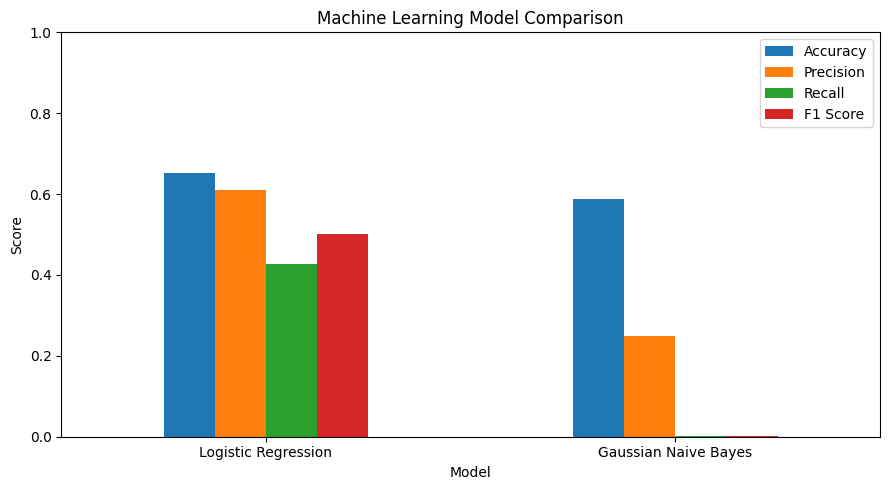

In [38]:

# Step 39: Compare Logistic Regression and Naive Bayes

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Gaussian Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, nb_pred)
    ],
    'Precision': [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, nb_pred, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, nb_pred, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, nb_pred, zero_division=0)
    ]
})

print("Machine Learning Model Comparison:")
print(results.round(4).to_string(index=False))

# Visualize performance
results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(9, 5))

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


In [39]:

# Step 40: Compare prediction distributions

from sklearn.metrics import confusion_matrix

print("Actual Test Labels:")
print(y_test.value_counts().sort_index())

print("\nLogistic Regression Predictions:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nNaive Bayes Predictions:")
print(pd.Series(nb_pred).value_counts().sort_index())

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nNaive Bayes Confusion Matrix:")
print(confusion_matrix(y_test, nb_pred))


Actual Test Labels:
Cost Growth Label
0    2078
1    1452
Name: count, dtype: int64

Logistic Regression Predictions:
0    2514
1    1016
Name: count, dtype: int64

Naive Bayes Predictions:
0    3526
1       4
Name: count, dtype: int64

Logistic Regression Confusion Matrix:
[[1682  396]
 [ 832  620]]

Naive Bayes Confusion Matrix:
[[2075    3]
 [1451    1]]


In [40]:

# Step 41: Logistic Regression with balanced class weights

balanced_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Balanced Logistic Regression Results")

print(classification_report(
    y_test, balanced_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))


Balanced Logistic Regression Results
              precision    recall  f1-score   support

           0       0.71      0.66      0.68      2078
           1       0.56      0.62      0.59      1452

    accuracy                           0.64      3530
   macro avg       0.64      0.64      0.64      3530
weighted avg       0.65      0.64      0.64      3530

Confusion Matrix:
[[1366  712]
 [ 549  903]]


In [41]:

# Step 42: Final comparison of all three models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

predictions = {
    'Logistic Regression': y_pred,
    'Gaussian Naive Bayes': nb_pred,
    'Balanced Logistic Regression': balanced_pred
}

comparison = []

for name, predictions_array in predictions.items():
    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions_array),
        'Precision': precision_score(
            y_test, predictions_array, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions_array, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, predictions_array, zero_division=0
        )
    })

final_results = pd.DataFrame(comparison)

print("Final Preliminary Model Comparison:")
print(final_results.round(4).to_string(index=False))


Final Preliminary Model Comparison:
                       Model  Accuracy  Precision  Recall  F1 Score
         Logistic Regression    0.6521     0.6102  0.4270    0.5024
        Gaussian Naive Bayes    0.5881     0.2500  0.0007    0.0014
Balanced Logistic Regression    0.6428     0.5591  0.6219    0.5888
